# prevision avec statsmodels : STLForecast

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.forecasting.stl import STLForecast
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import STL

from series_utils import generate_series, generate_series_ar, rmse

## 1. serie synthetique et plancher de bruit



In [2]:
n = 24 * 200
periode = 24
sigma_vrai = 1.0

t, valeurs = generate_series(n_points=n, trend_slope=0.001, seasonal_amplitude=5,seasonal_period=periode, noise_std=sigma_vrai,rng=np.random.default_rng(0))
serie_synth = pd.Series(valeurs, index=pd.date_range("2020-01-01", periods=n, freq="h"))

split_s = int(n * 0.8)
horizon_s = 168
train_s = serie_synth.iloc[:split_s]
reel_s = serie_synth.iloc[split_s:split_s + horizon_s]

prevision_s = STLForecast(train_s, ARIMA, model_kwargs=dict(order=(2, 0, 0)), period=periode).fit().forecast(horizon_s)
print("RMSE / sigma :", round(rmse(reel_s, prevision_s) / sigma_vrai, 3))


RMSE / sigma : 2.443


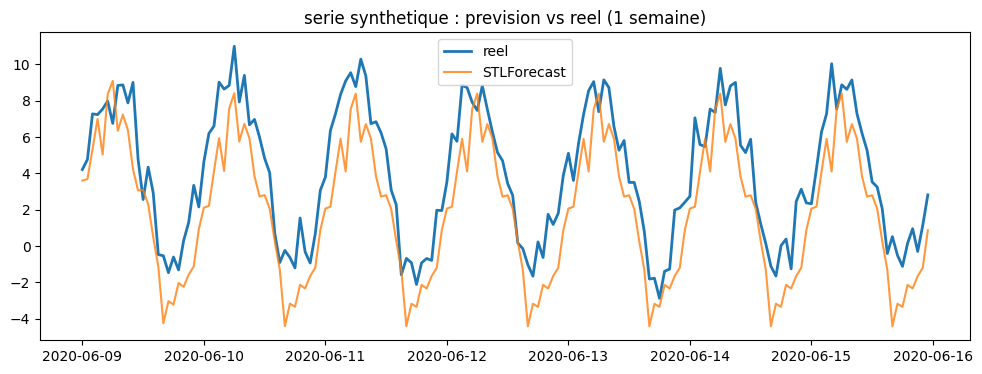

In [3]:
plt.figure(figsize=(12, 4))
plt.plot(reel_s.index, reel_s.to_numpy(), label="reel", linewidth=2)
plt.plot(reel_s.index, prevision_s.to_numpy(), label="STLForecast", alpha=0.8)
plt.title("serie synthetique : prevision vs reel (1 semaine)")
plt.legend()
plt.show()

tjrs un écart de qq degrés en dessous de la courbe réelle.

## 2. la serie desaisonnalisee

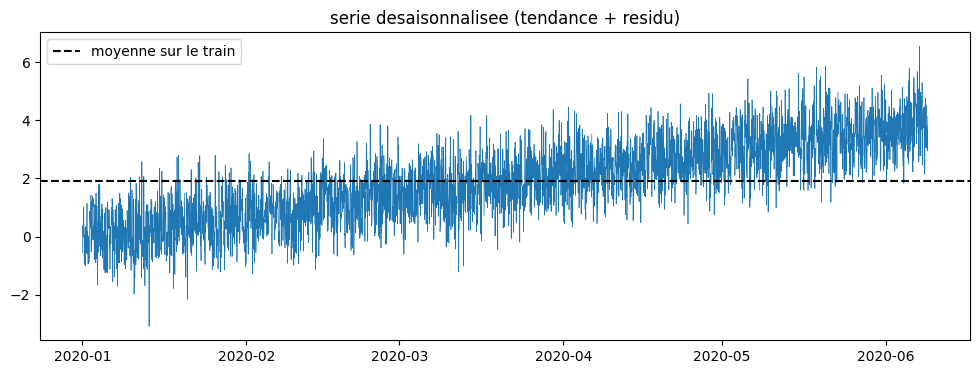

moyenne sur le train   : 1.901
niveau en fin de train : 3.746
ecart                  : 1.845


In [4]:
res_stl = STL(train_s, period=periode).fit()
desaisonnalisee = res_stl.trend + res_stl.resid

plt.figure(figsize=(12, 4))
plt.plot(desaisonnalisee.index, desaisonnalisee.to_numpy(), linewidth=0.5)
plt.axhline(float(desaisonnalisee.mean()), color="k", linestyle="--", label="moyenne sur le train")
plt.title("serie desaisonnalisee (tendance + residu)")
plt.legend()
plt.show()

print("moyenne sur le train   :", round(float(desaisonnalisee.mean()), 3))
print("niveau en fin de train :", round(float(desaisonnalisee.iloc[-24:].mean()), 3))
print("ecart                  :", round(float(desaisonnalisee.iloc[-24:].mean() - desaisonnalisee.mean()), 3))

## 3. correction avec d = 1

le probleme vient de d = 0 .le modele suppose une moyenne fixe, donc il fait redescendre sa prevision vers la moyenne du train alors que la serie monte.

la serie monte de 0.001 par heure : ses niveaux changent sans arret, mais sa variation vaut toujours 0.001.

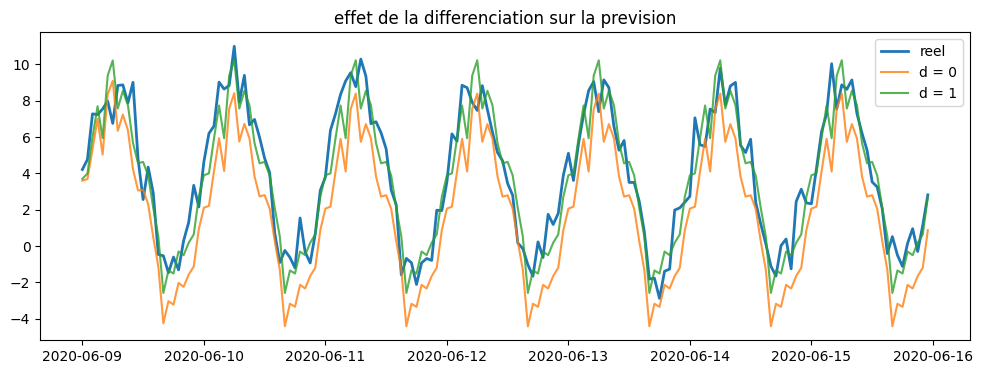

d = 0 : RMSE / sigma 2.443   decalage moyen -2.034
d = 1 : RMSE / sigma 1.359   decalage moyen -0.274
coefficients appris : {'ar.L1': -0.6636, 'ar.L2': -0.3306, 'sigma2': 0.8429}


In [5]:
ORDRE = dict(order=(2, 1, 0))
modele_source = STLForecast(train_s, ARIMA, model_kwargs=ORDRE, period=periode).fit()
prevision_d1 = modele_source.forecast(horizon_s)

plt.figure(figsize=(12, 4))
plt.plot(reel_s.index, reel_s.to_numpy(), label="reel", linewidth=2)
plt.plot(reel_s.index, prevision_s.to_numpy(), label="d = 0", alpha=0.8)
plt.plot(reel_s.index, prevision_d1.to_numpy(), label="d = 1", alpha=0.8)
plt.title("effet de la differenciation sur la prevision")
plt.legend()
plt.show()

print("d = 0 : RMSE / sigma", round(rmse(reel_s, prevision_s) / sigma_vrai, 3),
      "  decalage moyen", round(float(np.mean(np.asarray(prevision_s) - np.asarray(reel_s))), 3))
print("d = 1 : RMSE / sigma", round(rmse(reel_s, prevision_d1) / sigma_vrai, 3),
      "  decalage moyen", round(float(np.mean(np.asarray(prevision_d1) - np.asarray(reel_s))), 3))
print("coefficients appris :", {k: round(float(v), 4) for k, v in modele_source.model_result.params.items()})

## 4. changer les parametres de la serie



In [6]:
phi1 = float(modele_source.model_result.params["ar.L1"])
phi2 = float(modele_source.model_result.params["ar.L2"])

balayage = [("trend_slope", [0.0, 0.001, 0.005, 0.02]),
            ("seasonal_amplitude", [1, 5, 10, 20]),
            ("seasonal_period", [12, 24, 48, 168]),
            ("noise_std", [0.5, 1.0, 2.0, 4.0])]

lignes = []
for nom, valeurs in balayage:
    for v in valeurs:
        p = dict(n_points=n, trend_slope=0.001, seasonal_amplitude=5,seasonal_period=periode, noise_std=sigma_vrai)
        p[nom] = v
        _, y = generate_series(rng=np.random.default_rng(1), **p)
        cible = pd.Series(y, index=serie_synth.index)
        vrai = cible.iloc[split_s:split_s + horizon_s]

        d = STL(cible.iloc[:split_s], period=periode).fit()
        des = np.asarray(d.trend + d.resid)

        dz = np.diff(des)
        d1, d2, niveau = dz[-1], dz[-2], des[-1]
        prev = []
        for _ in range(horizon_s):
            dnew = phi1 * d1 + phi2 * d2
            niveau = niveau + dnew
            prev.append(niveau)
            d2, d1 = d1, dnew

        saison = np.tile(np.asarray(d.seasonal)[-periode:], horizon_s // periode + 1)[:horizon_s]
        prev_transfert = np.array(prev) + saison

        prev_reajuste = STLForecast(cible.iloc[:split_s], ARIMA, model_kwargs=ORDRE, period=periode).fit().forecast(horizon_s)

        lignes.append([nom, v, round(rmse(vrai, prev_transfert) / p["noise_std"], 3), round(rmse(vrai, prev_reajuste) / p["noise_std"], 3)])

table = pd.DataFrame(lignes, columns=["parametre", "valeur", "transfert", "reajuste"])
table["ecart"] = (table["transfert"] - table["reajuste"]).round(3)
print(table.to_string(index=False))

         parametre  valeur  transfert  reajuste  ecart
       trend_slope   0.000      1.462     1.462  0.000
       trend_slope   0.001      1.435     1.435  0.000
       trend_slope   0.005      1.393     1.393  0.000
       trend_slope   0.020      2.057     2.057  0.000
seasonal_amplitude   1.000      1.435     1.435  0.000
seasonal_amplitude   5.000      1.435     1.435  0.000
seasonal_amplitude  10.000      1.435     1.435  0.000
seasonal_amplitude  20.000      1.435     1.435  0.000
   seasonal_period  12.000      1.435     1.435  0.000
   seasonal_period  24.000      1.435     1.435  0.000
   seasonal_period  48.000      5.644     5.556  0.088
   seasonal_period 168.000      5.560     5.557  0.003
         noise_std   0.500      1.414     1.414  0.000
         noise_std   1.000      1.435     1.435  0.000
         noise_std   2.000      1.447     1.447  0.000
         noise_std   4.000      1.454     1.454  0.000


## 5. changer le bruit avec une memoire


 phi cible  transfert  reajuste  ecart %
       0.9     0.8516    0.8507     0.11
       0.6     0.9290    0.8976     3.50
       0.3     1.0378    0.9397    10.44
       0.0     1.1941    0.9690    23.23


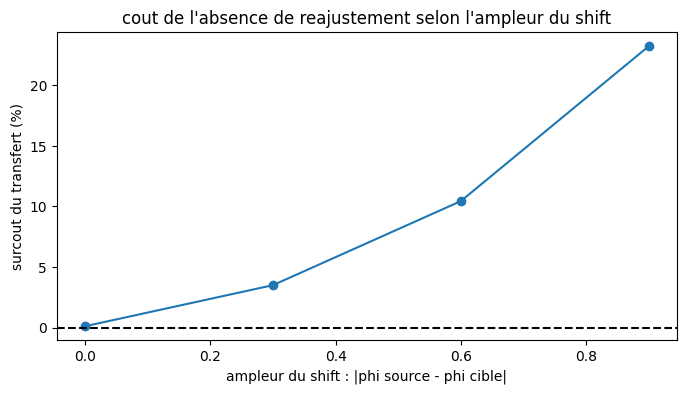

In [7]:
phi_source = 0.9
n_origines = 300
commun = dict(n_points=n, trend_slope=0.001, seasonal_amplitude=5,
              seasonal_period=periode, noise_std=sigma_vrai)

_, y = generate_series_ar(phi=phi_source, rng=np.random.default_rng(0), **commun)
source_ar = pd.Series(y, index=serie_synth.index)
modele_ar = STLForecast(source_ar.iloc[:split_s], ARIMA, model_kwargs=ORDRE, period=periode).fit()

lignes = []
for phi in [0.9, 0.6, 0.3, 0.0]:
    _, y = generate_series_ar(phi=phi, rng=np.random.default_rng(1), **commun)
    cible = pd.Series(y, index=serie_synth.index)
    d = STL(cible, period=periode).fit()
    des = np.asarray(d.trend + d.resid)
    dz = np.diff(des)
    t = np.arange(split_s, split_s + n_origines)
    vrai = des[t]

    modele_cible = STLForecast(cible.iloc[:split_s], ARIMA, model_kwargs=ORDRE, period=periode).fit()

    erreurs = []
    for modele in [modele_ar, modele_cible]:
        a = float(modele.model_result.params["ar.L1"])
        b = float(modele.model_result.params["ar.L2"])
        erreurs.append(rmse(des[t - 1] + a * dz[t - 2] + b * dz[t - 3], vrai))

    lignes.append([phi, round(erreurs[0], 4), round(erreurs[1], 4),
                   round(100 * (erreurs[0] - erreurs[1]) / erreurs[1], 2)])

table_ar = pd.DataFrame(lignes, columns=["phi cible", "transfert", "reajuste", "ecart %"])
print(table_ar.to_string(index=False))

plt.figure(figsize=(8, 4))
plt.plot((phi_source - table_ar["phi cible"]).abs(), table_ar["ecart %"], marker="o")
plt.axhline(0, color="k", linestyle="--")
plt.xlabel("ampleur du shift : |phi source - phi cible|")
plt.ylabel("surcout du transfert (%)")
plt.title("cout de l'absence de reajustement selon l'ampleur du shift")
plt.show()

## 6. balayage des ordres ARIMA

on revient a la serie de reference et on fait varier l'ordre (p, d, q)

/Users/arnaudgrassian/Downloads/stage_recherche/.venv/lib/python3.9/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'


ordre (p,d,q)  RMSE/sigma  biais
    (1, 0, 0)       2.473 -2.080
    (2, 0, 0)       2.443 -2.034
    (3, 0, 0)       2.398 -1.976
    (0, 1, 0)       1.338  0.132
    (1, 1, 0)       1.334 -0.079
    (2, 1, 0)       1.359 -0.274
    (3, 1, 0)       1.393 -0.406
    (0, 1, 1)       1.338 -0.124
    (1, 1, 1)       1.338 -0.124
    (2, 1, 1)       1.338 -0.125
    (2, 1, 2)       1.339 -0.125
    (2, 2, 0)      45.978 39.826


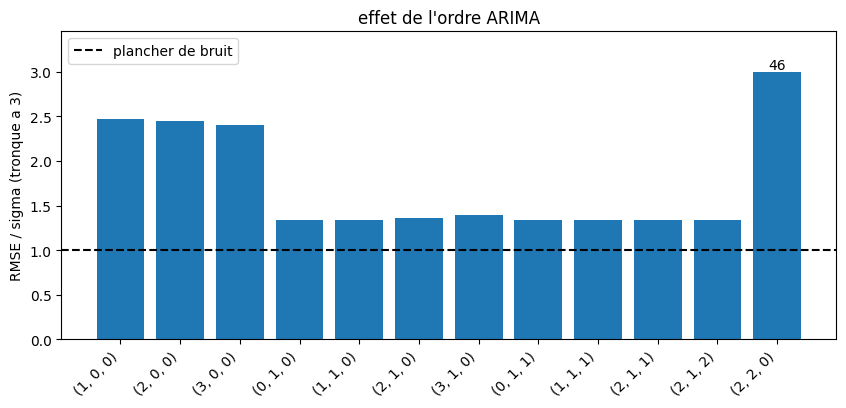

In [8]:
ordres = [(1, 0, 0), (2, 0, 0), (3, 0, 0),
          (0, 1, 0), (1, 1, 0), (2, 1, 0), (3, 1, 0),
          (0, 1, 1), (1, 1, 1), (2, 1, 1), (2, 1, 2),
          (2, 2, 0)]

lignes = []
for o in ordres:
    prev = STLForecast(train_s, ARIMA, model_kwargs=dict(order=o), period=periode).fit().forecast(horizon_s)
    biais = float(np.mean(np.asarray(prev) - np.asarray(reel_s)))
    lignes.append([str(o), round(rmse(reel_s, prev) / sigma_vrai, 3), round(biais, 3)])

table_ordres = pd.DataFrame(lignes, columns=["ordre (p,d,q)", "RMSE/sigma", "biais"])
print(table_ordres.to_string(index=False))

plafond = 3.0
plt.figure(figsize=(10, 4))
plt.bar(table_ordres["ordre (p,d,q)"], table_ordres["RMSE/sigma"].clip(upper=plafond))
for i, v in enumerate(table_ordres["RMSE/sigma"]):
    if v > plafond:
        plt.text(i, plafond, f"{v:.0f}", ha="center", va="bottom")
plt.axhline(1.0, color="k", linestyle="--", label="plancher de bruit")
plt.ylim(0, plafond * 1.15)
plt.ylabel("RMSE / sigma (tronque a 3)")
plt.title("effet de l'ordre ARIMA")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.show()

## 7. balayage des types de modeles



In [9]:
from statsmodels.tsa.ar_model import AutoReg

modeles = [("ARIMA(2,0,0)", ARIMA, dict(order=(2, 0, 0))),
           ("ARIMA(2,1,0)", ARIMA, dict(order=(2, 1, 0))),
           ("ARIMA(1,1,1)", ARIMA, dict(order=(1, 1, 1))),
           ("AutoReg(3) trend=ct", AutoReg, dict(lags=3, trend="ct")),
           ("AutoReg(24) trend=ct", AutoReg, dict(lags=24, trend="ct"))]

phi_memoire = 0.9
_, y = generate_series_ar(phi=phi_memoire, rng=np.random.default_rng(1), **commun)
cible_memoire = pd.Series(y, index=serie_synth.index)

plancher_blanc = sigma_vrai
plancher_memoire = sigma_vrai * np.sqrt((1 - phi_memoire ** (2 * horizon_s)) / (1 - phi_memoire ** 2))
print(f"plancher a l'horizon {horizon_s} : bruit blanc {plancher_blanc:.3f}, bruit autocorrele {plancher_memoire:.3f}")

lignes = []
for nom, classe, kw in modeles:
    ligne = [nom]
    for train, vrai, plancher in [(train_s, reel_s, plancher_blanc), (cible_memoire.iloc[:split_s],  cible_memoire.iloc[split_s:split_s + horizon_s], plancher_memoire)]:
        prev = STLForecast(train, classe, model_kwargs=kw, period=periode).fit().forecast(horizon_s)
        ligne.append(round(rmse(vrai, prev) / plancher, 3))
    lignes.append(ligne)

print(pd.DataFrame(lignes, columns=["modele", "bruit blanc", "bruit autocorrele phi=0.9"]).to_string(index=False))

plancher a l'horizon 168 : bruit blanc 1.000, bruit autocorrele 2.294


              modele  bruit blanc  bruit autocorrele phi=0.9
        ARIMA(2,0,0)        2.443                      1.300
        ARIMA(2,1,0)        1.359                      1.711
        ARIMA(1,1,1)        1.338                      1.184
 AutoReg(3) trend=ct        1.339                      1.213
AutoReg(24) trend=ct        1.319                      1.204


## 8. transferer un arima source vers un ordre cible different

source (2, 0, 0) fournit : {'const': 1.9002, 'ar.L1': 0.4025, 'ar.L2': 0.3996, 'sigma2': 0.8842}
cible  (2, 1, 1) attend  : ['ar.L1', 'ar.L2', 'ma.L1', 'sigma2']
mis a zero car absents de la source : ['ma.L1']

              methode  RMSE / sigma  biais moyen
  copie positionnelle           NaN          NaN
    transfert par nom         1.623        0.829
reajuste sur la cible         1.414       -0.255


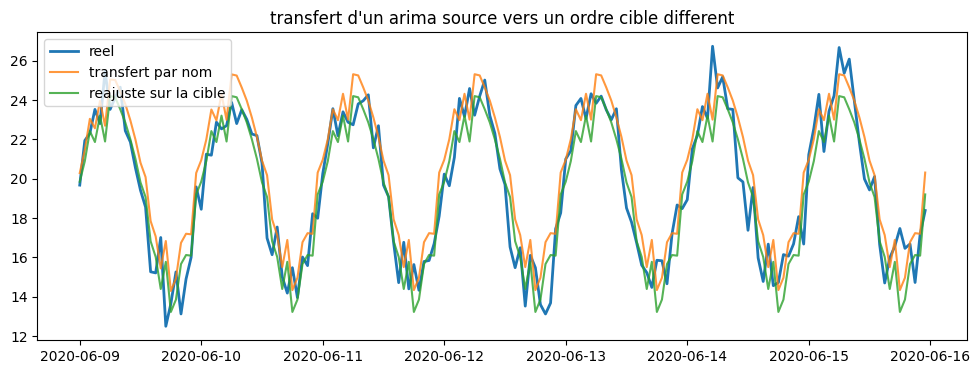

In [10]:
ordre_source = (2, 0, 0)
ordre_cible = (2, 1, 1)

_, y_cible = generate_series(n_points=n, trend_slope=0.005, seasonal_amplitude=5, seasonal_period=periode, noise_std=sigma_vrai, rng=np.random.default_rng(1))
serie_cible = pd.Series(y_cible, index=serie_synth.index)
reel_c = serie_cible.iloc[split_s:split_s + horizon_s]

d_source = STL(train_s, period=periode).fit()
arima_source = ARIMA(np.asarray(d_source.trend + d_source.resid), order=ordre_source).fit()
params_source = dict(zip(arima_source.model.param_names, np.asarray(arima_source.params)))

d_cible = STL(serie_cible.iloc[:split_s], period=periode).fit()
y_des = np.asarray(d_cible.trend + d_cible.resid)
saison_c = np.tile(np.asarray(d_cible.seasonal)[-periode:], horizon_s // periode + 1)[:horizon_s]
modele_cible = ARIMA(y_des, order=ordre_cible)

print("source", ordre_source, "fournit :", {k: round(float(v), 4) for k, v in params_source.items()})
print("cible ", ordre_cible, "attend  :", modele_cible.param_names)

params_nom = np.array([params_source.get(nom, 0.0) for nom in modele_cible.param_names])
absents = [nom for nom in modele_cible.param_names if nom not in params_source]
print("mis a zero car absents de la source :", absents)

previsions = {"copie positionnelle": modele_cible.filter(np.asarray(arima_source.params)).forecast(horizon_s),
              "transfert par nom": modele_cible.filter(params_nom).forecast(horizon_s),
              "reajuste sur la cible": ARIMA(y_des, order=ordre_cible).fit().forecast(horizon_s)}

lignes_tr = []
for nom in previsions:
    previsions[nom] = previsions[nom] + saison_c
    lignes_tr.append([nom, round(rmse(reel_c, previsions[nom]) / sigma_vrai, 3),
                      round(float(np.mean(previsions[nom] - reel_c.to_numpy())), 3)])

print()
print(pd.DataFrame(lignes_tr, columns=["methode", "RMSE / sigma", "biais moyen"]).to_string(index=False))

plt.figure(figsize=(12, 4))
plt.plot(reel_c.index, reel_c.to_numpy(), label="reel", linewidth=2)
for nom, prev in previsions.items():
    if np.isfinite(prev).all():
        plt.plot(reel_c.index, prev, label=nom, alpha=0.8)
plt.title("transfert d'un arima source vers un ordre cible different")
plt.legend()
plt.show()